<a href="https://colab.research.google.com/github/jiminchoi2007/jimin/blob/main/2026130208_%EC%B5%9C%EC%A7%80%EB%AF%BC_%EA%B3%BC%EC%A0%9C3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 과제 3 — 내 데이터로 모델 하나 만들기
**데이터과학과 인공지능 · 2026-2학기 · 10주차**

| 항목 | 내용 |
|---|---|
| **마감** | **2026년 11월 12일(목) 23:59** |
| 제출처 | LMS 과제 게시판 |
| 파일명 | `학번_이름_과제3.ipynb` |
| 배점 | 10점 — **세 경로 모두 만점 가능** |

### 노트북 작성법

1. 아래 **0절**에서 내 경로를 고릅니다
2. **내 경로의 절만** 채웁니다. 다른 경로 절은 비워 둬도 됩니다
3. **6절 답안 다섯 칸**은 모든 경로가 씁니다
4. 맨 위 메뉴 **런타임 → 모두 실행** 후, 결과가 보이는 상태로 **파일 → 다운로드 → .ipynb**

> 학번·이름: 2026130208 최지민

---
## 0. 내 경로 고르기

먼저 내 데이터를 보고 아래 순서대로 판단하세요.

| 질문 | 예 | 아니오 |
|---|---|---|
| ① 맞히고 싶은 열(y)이 있나? | ②로 | **아무 열이나 y로 정해 보세요.** 다른 열로 그 열을 맞힐 수 있을까? |
| ② 숫자 열이 하나라도 있나? | ③으로 | 글을 **세어서** 숫자로 만들 수 있나? (글자 수, 특정 단어 개수) — 5주차 |
| ③ 코드가 부담스러운가? | **A 경로** (구글 시트) | **B 경로** (이 노트북 코드) |
| 그래도 y를 못 찾았다 | **C 경로** — 설계는 내 데이터로, 모델은 수업 데이터로 | |

> **숫자 열이 연도 하나뿐이어도** A 경로가 됩니다. 연도 → 출생아 수, 연도 → 관객 수처럼 연도를 x로 쓰면 됩니다.

### 내 경로는? (하나만 남기고 지우세요)

**A** / **B** / **C**

---
## 1. 공통 준비 — 실행만 하세요

In [3]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib
import matplotlib.pyplot as plt
import pandas as pd

---
## 2. 🅰 A 경로 — 구글 시트 (코드 없음)

1. 내 데이터에서 **숫자 열 두 개**를 골라 구글 시트에 올립니다
   - 하나는 **맞히려는 것 (y)**, 하나는 **보고 맞힐 것 (x)**
2. 두 열 선택 → **삽입 → 차트 → 분산형**
3. **맞춤설정 → 계열 → 추세선 체크 → 라벨: 방정식 사용**
4. 빈 칸에 `=RSQ(y범위, x범위)` 와 `=FORECAST(새값, y범위, x범위)` 를 넣어 봅니다
5. 시트 **공유 → 링크가 있는 모든 사용자 · 뷰어**

아래 칸을 채우세요.

**시트 링크**: https://docs.google.com/spreadsheets/d/1pUnnUOIb05MAD_f0y0vKX7AuD2J0RzJKf-4ir-m9eZw/edit?usp=sharing

**추세선 방정식**: y = -17000x + 490000

**RSQ 값**: 1

**FORECAST 예측**: x가 1.5일 때 y는 235000 (이 x는 데이터 범위 안인가요? 예 )

**차트 캡처**: 아래 이미지를 이 칸에 끌어다 놓으세요 (Colab 텍스트 칸에 이미지 붙여넣기 가능)


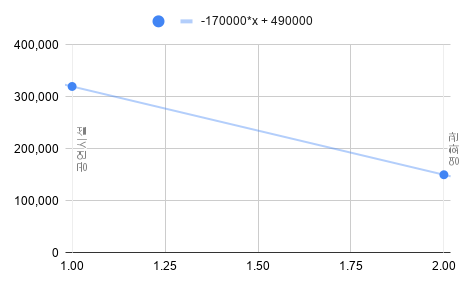

---
## 3. 🅱 B 경로 — 노트북 코드

### 3.1. 내 데이터 불러오기
왼쪽 📁 폴더 아이콘 → 업로드 → 파일 이름을 아래에 맞게 고치세요.

In [2]:
내df = pd.read_csv("내파일.csv")      # ← 파일 이름 고치기
print(내df.shape)
내df.head()

FileNotFoundError: [Errno 2] No such file or directory: '내파일.csv'

### 3.2. 빈칸 처리 (6주차)
쓸 열만 골라서 빈칸이 있는 줄을 지웁니다.

In [ ]:
쓸열 = ["열1", "열2", "맞힐열"]          # ← 내 열 이름으로
깨끗 = 내df[쓸열].dropna()
print(len(내df), "→", len(깨끗), "줄")

### 3.3. 모델 만들기
**회귀 또는 분류 중 하나만** 남기고, 다른 쪽은 지우세요.

In [ ]:
# ── 무엇을 맞힐까 (y) ─────────────────────
y = 깨끗["맞힐열"]

# ── 무엇을 보고 맞힐까 (X) — 글자 열은 get_dummies가 0/1로 펼쳐줍니다 ──
X = pd.get_dummies(깨끗[["열1", "열2"]])

# ── 숫자를 맞힌다면 (회귀) ─────────────────
from sklearn.linear_model import LinearRegression
내모델 = LinearRegression()

# ── 이름표를 맞힌다면 (분류) ───────────────
# from sklearn.tree import DecisionTreeClassifier
# 내모델 = DecisionTreeClassifier(max_depth=3, random_state=10)

내모델.fit(X, y)
print("학습 완료")

### 3.4. 예측값과 실제값 나란히 보기

In [ ]:
결과 = pd.DataFrame({"실제": y, "예측": 내모델.predict(X)})
결과.head(10).round(1)

### 3.5. (분류를 골랐다면) 규칙 그림 보기
회귀를 골랐다면 이 칸은 건너뛰세요.

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(14, 7))
plot_tree(내모델, feature_names=X.columns, class_names=[str(c) for c in 내모델.classes_],
          filled=True, fontsize=10, impurity=False, rounded=True)
plt.show()

### 막힐 때

| 오류 메시지 | 원인 | 해결 |
|---|---|---|
| `KeyError: '열1'` | 열 이름이 다르다 | `내df.columns` 로 정확한 이름 확인 |
| `could not convert string to float` | X에 글자 열 | `pd.get_dummies(...)` 로 감싸기 |
| `Expected 2D array` | X를 대괄호 한 겹으로 | `깨끗[["열"]]` 두 겹으로 |
| `Input contains NaN` | 빈칸 | 3.2절 `dropna()` 실행했는지 확인 |
| `Unknown label type` | y가 숫자인데 분류 모델 | 회귀 모델로 바꾸기 |

---
## 4. 🅲 C 경로 — 설계는 내 데이터로, 모델은 수업 데이터로

**내 데이터로 회귀·분류를 하기 어려운 학생**을 위한 경로입니다. 감점 없습니다.

### 4.1. 내 데이터로 설계하기 (글로)

| 질문 | 내 답 |
|---|---|
| 내 데이터는 무엇인가 (출처, 줄 수, 주요 열) | |
| 이 데이터로 무엇을 맞히고 싶은가 (y) | |
| 그걸 맞히려면 무엇을 보면 될 것 같은가 (X) | |
| 회귀인가 분류인가, 왜? | |
| **지금 데이터로는 왜 안 되는가** | |
| **어떤 열이 더 있으면 되는가, 그건 어디서 구할 수 있나** | |

> 정답 열(y)이 아예 없는 데이터라면, 그건 **비지도 학습**용 데이터입니다(9주차). 12주차 군집화에서 쓸 수 있습니다. 그렇게 판단한 이유를 쓰면 됩니다.

### 4.2. 수업 데이터로 모델 하나 만들기
카페 데이터를 불러옵니다. **실행만** 하세요.

In [ ]:
# 설정 셀 — 그냥 실행만 하세요 (이 코드는 몰라도 됩니다)
import random
random.seed(77)

메뉴정보 = {
    "아메리카노": ("커피", 4500), "카페라떼": ("커피", 5000),
    "바닐라라떼": ("커피", 5500), "콜드브루": ("커피", 5000),
    "녹차라떼": ("논커피", 5500), "초코라떼": ("논커피", 5500),
    "자몽에이드": ("논커피", 6000), "복숭아아이스티": ("논커피", 4500),
}
요일표 = ["월", "화", "수", "목", "금"]
요일효과 = {"월": -3, "화": -2, "수": 0, "목": 2, "금": 6}

좋은후기 = ["맛이 깔끔하고 좋았어요", "직원분이 친절하셨습니다", "자리가 넓어서 공부하기 좋아요",
          "가격 대비 양이 넉넉합니다", "향이 진하고 맛있어요", "분위기가 조용해서 좋네요"]
보통후기 = ["무난한 맛입니다", "그냥 평범했어요", "가격은 적당한 편", "다시 올지는 모르겠네요"]
나쁜후기 = ["대기 시간이 너무 길었어요", "자리가 없어서 서서 마셨어요", "주문이 잘못 나왔어요",
          "너무 붐벼서 정신없었어요", "맛이 생각보다 밍밍합니다"]

# 2026-03-02(월) ~ 2026-04-24(금), 평일 40일
달일수 = {3: 31, 4: 30}
날짜들 = []
월, 일 = 3, 2
while len(날짜들) < 40:
    주차인덱스 = len(날짜들) % 5
    날짜들.append((월, 일, 요일표[주차인덱스]))
    일 += 3 if 주차인덱스 == 4 else 1      # 금요일 다음은 월요일
    if 일 > 달일수[월]:
        일 -= 달일수[월]
        월 += 1

행들 = ["날짜,요일,기온,매장,메뉴,분류,가격,수량,결제수단,평점,후기"]
for 차례, (월, 일, 요일) in enumerate(날짜들):
    날짜 = f"2026-{월:02d}-{일:02d}"
    기온 = round(7 + (차례 / 39) * 11 + random.gauss(0, 2.2), 1)
    for 매장 in ["안암점", "정문점"]:
        매장효과 = 3 if 매장 == "안암점" else 0
        for 메뉴 in random.sample(list(메뉴정보), 3):
            분류, 가격 = 메뉴정보[메뉴]
            기온효과 = (기온 - 12) * (1.9 if 분류 == "논커피" else -0.7)
            수량 = 24 + 기온효과 + 요일효과[요일] + 매장효과 + random.gauss(0, 4)
            수량 = max(4, round(수량))
            결제 = random.choice(["카드", "현금", "간편결제"])
            # 붐비는 날일수록 불만이 늘어납니다
            불만가중 = min(30, max(0, 수량 - 28))
            평점 = random.choices([1, 2, 3, 4, 5],
                                weights=[2 + 불만가중 * 0.5, 5 + 불만가중 * 0.8,
                                         18 + 불만가중 * 0.4, 40, 30])[0]
            후기 = random.choice(좋은후기 if 평점 >= 4 else (보통후기 if 평점 == 3 else 나쁜후기))
            행들.append(f"{날짜},{요일},{기온},{매장},{메뉴},{분류},{가격},{수량},{결제},{평점},{후기}")

# 단체 주문 2건 — 나중에 박스플롯에서 다시 만나게 됩니다
행들.append("2026-04-10,금,17.2,안암점,아메리카노,커피,4500,168,카드,4,맛이 깔끔하고 좋았어요")
행들.append("2026-03-27,금,13.8,정문점,카페라떼,커피,5000,140,간편결제,3,무난한 맛입니다")

with open("cafe_sales_8weeks.csv", "w", encoding="utf-8") as f:
    f.write("\n".join(행들))

print(f"cafe_sales_8weeks.csv 생성 완료 — 총 {len(행들) - 1}행")

In [ ]:
df = pd.read_csv("cafe_sales_8weeks.csv")
일반 = df[df["수량"] < 100].copy()      # 단체 주문 2건 제외
일반.head(3)

아래 **두 칸 중 하나**를 골라, `# ←` 표시된 곳을 **수업 시간과 다르게** 바꿔 보세요.

- 회귀: 커피로 바꾸기, 매장 하나만 보기 등
- 분류: X에 `매장`·`결제수단` 넣어보기, `max_depth` 바꾸기 등

In [ ]:
# ── 회귀: 기온으로 판매량 맞히기 ──
from sklearn.linear_model import LinearRegression

고른것 = 일반[일반["분류"] == "논커피"]                  # ← "커피"로 바꿔 보기
날짜별 = 고른것.groupby("날짜").agg(기온=("기온", "first"),
                               평균판매량=("수량", "mean")).reset_index()
모델 = LinearRegression()
모델.fit(날짜별[["기온"]], 날짜별["평균판매량"])
print("기울기:", round(float(모델.coef_[0]), 2), "  절편:", round(float(모델.intercept_), 2))

In [ ]:
# ── 분류: 많이 팔릴까 적게 팔릴까 ──
from sklearn.tree import DecisionTreeClassifier, plot_tree

일반["실제"] = "적게"
일반.loc[일반["수량"] > 일반["수량"].median(), "실제"] = "많이"

X = pd.get_dummies(일반[["기온", "요일", "분류"]])          # ← 열을 바꿔 보기
나무 = DecisionTreeClassifier(max_depth=2, random_state=10)  # ← 숫자 바꿔 보기
나무.fit(X, 일반["실제"])

plt.figure(figsize=(12, 6))
plot_tree(나무, feature_names=X.columns, class_names=나무.classes_,
          filled=True, fontsize=11, impurity=False, rounded=True)
plt.show()

---
## 5. 답안 — 모든 경로 공통

각 칸을 더블클릭해서 쓰세요. **C 경로는 ①②③을 4.1절 설계 기준으로, ④⑤를 4.2절 결과 기준으로** 쓰면 됩니다.

### ① 무엇을 맞히려 했는가
y로 고른 열과, 왜 그 열인지

> (여기에 쓰세요)

### ② 무엇을 보고 맞혔는가
X로 고른 열과, 왜 그 열인지. **예측하는 시점에 알 수 있는 정보인지**도 한 줄로.

> (여기에 쓰세요)

### ③ 어떤 종류의 문제인가
회귀인가 분류인가, 왜 그렇게 판단했는지. A 경로는 **기울기의 뜻을 내 데이터 단위로** 한 문장.

> (여기에 쓰세요)

### ④ 예측 결과
B·C 경로: 예측값과 실제값을 나란히 본 결과 / A 경로: FORECAST 예측 한 개

> (여기에 쓰세요)

### ⑤ 그럴듯한가 — 세 문장
결과를 보고 든 생각을 세 문장으로. 기울기가 원인처럼 읽히지 않는지, 데이터 범위 밖 예측은 아닌지도 생각해 보세요.

> 1.
> 2.
> 3.

---
## 6. 제출 전 체크

- [ ] 0절에서 내 경로 하나만 남겼다
- [ ] 내 경로의 절을 채웠다 (A: 링크 + 캡처 / B: 실행 결과 / C: 설계 표 + 모델 결과)
- [ ] 5절 답안 다섯 칸을 모두 썼다
- [ ] **런타임 → 모두 실행** 후 오류가 없다 (A 경로는 생략 가능)
- [ ] 파일명 `학번_이름_과제3.ipynb`

### 채점 기준 (세 경로 공통)

| 항목 | 배점 |
|---|---|
| 모델이 실제로 만들어졌는가 (시트 추세선 / 코드 실행 / 수업 데이터 모델) | 2 |
| 맞힐 것과 볼 것을 올바르게 구분했는가 | 2 |
| 왜 그 변수를 골랐는지 설명했는가 | 3 |
| 결과를 보고 쓴 세 문장 | 3 |
| **합계** | **10** |

> 정확도는 채점하지 않습니다. C 경로는 "왜 내 데이터로는 안 되는가"를 잘 쓰면 ②·③ 항목 만점이 가능합니다.